# Diagnóstico de cancro da mama — Explicabilidade com Grad-CAM

**Inteligência Artificial Centrada no Humano** · Mestrado em Inteligência Artificial e Engenharia de Dados · FCTUC

O notebook 01 mostra *o que* o modelo erra; este mostra *em que zona da ecografia* se baseou para decidir. Para um médico confiar (ou desconfiar) de uma previsão, não basta a classe: é preciso ver se o modelo olhou para a lesão ou para outra coisa (anotações do ecógrafo, bordas da imagem, tecido à volta). Como o dataset traz o contorno das lesões desenhado por médicos, podemos também **medir** se o modelo olha para a lesão.

## 1. Configuração

Como no notebook 01. Usa a MobileNetV2 guardada pelo notebook 01 em `models/mobilenet.keras` (seed 1): se o ficheiro não existir, é preciso correr o notebook 01 primeiro.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent   # raiz do repositório (o notebook está em notebooks/)
sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, MODELS_PATH
from src.gpu import setup_gpu

setup_gpu()

A treinar na GPU: NVIDIA GeForce RTX 3050 Laptop GPU


True

## 2. Modelo e dados

A mesma divisão do notebook 01 (mesma seed), por isso as mesmas 149 imagens de teste, que o modelo nunca viu. Para cada imagem de teste carrega-se também a **máscara da lesão** (`load_lesion_mask` em `src/data.py`): o contorno desenhado pelos médicos que anotaram o dataset. As imagens normais não têm lesão.

In [2]:
import numpy as np
from src.data import CLASSES, load_dataset, load_lesion_mask
from src.evaluation import MALIGNANT, compute_metrics
from src.explain import GradCAM, load_model

IMG_SIZE = 128
_, _, x_test, _, _, y_test, names_test = load_dataset(DATA_PATH, size=IMG_SIZE, test_names=True)
masks = np.array([load_lesion_mask(DATA_PATH, name, IMG_SIZE) for name in names_test])

model = load_model(MODELS_PATH / "mobilenet.keras")
probs_test = model.predict(x_test, verbose=0)
y_pred = probs_test.argmax(axis=1)
print("Métricas no teste (devem ser as da seed 1 no notebook 01):", compute_metrics(y_test, y_pred))

Métricas no teste (devem ser as da seed 1 no notebook 01): {'accuracy': 0.7986577181208053, 'recall_malignant': 0.7435897435897436, 'false_negatives': 10}


## 3. Como funciona o Grad-CAM

O Grad-CAM responde à pergunta "que zonas da imagem fizeram subir a probabilidade desta classe?" (`GradCAM` em `src/explain.py`):

1. A imagem passa pela MobileNetV2 até à última camada convolucional. Em imagens 128×128, esta camada divide a imagem numa grelha de **4×4 zonas** e dá, para cada zona, 1280 números (*features*) que descrevem o que lá está (texturas, contornos…).
2. A camada final do modelo dá um **peso** a cada feature para cada classe.
3. O mapa de uma classe é, em cada zona, a soma das features multiplicadas pelos pesos dessa classe. Ficam só os valores positivos (as zonas que **fazem subir** a classe), normalizados para [0, 1] e ampliados para o tamanho da imagem.

O Grad-CAM, em geral, calcula os pesos com gradientes; nesta rede os gradientes são exatamente os pesos da camada final (a menos de uma constante), por isso o mapa é o mesmo sem os calcular. A grelha 4×4 é grosseira: o mapa mostra a **região** que o modelo usou, não o contorno exato da lesão.

## 4. Exemplos

Em cada par: à esquerda a ecografia, à direita o Grad-CAM da classe **prevista** (vermelho = zona mais importante). O contorno branco é a lesão desenhada pelos médicos. O título diz a classe prevista e a probabilidade que o modelo lhe deu (verde = certo, vermelho = errado).

/home/httpirsh/Documentos/Mestrado/IACH/Projeto/.venv/lib64/python3.11/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 128, 128, 1))
  warnings.warn(msg)


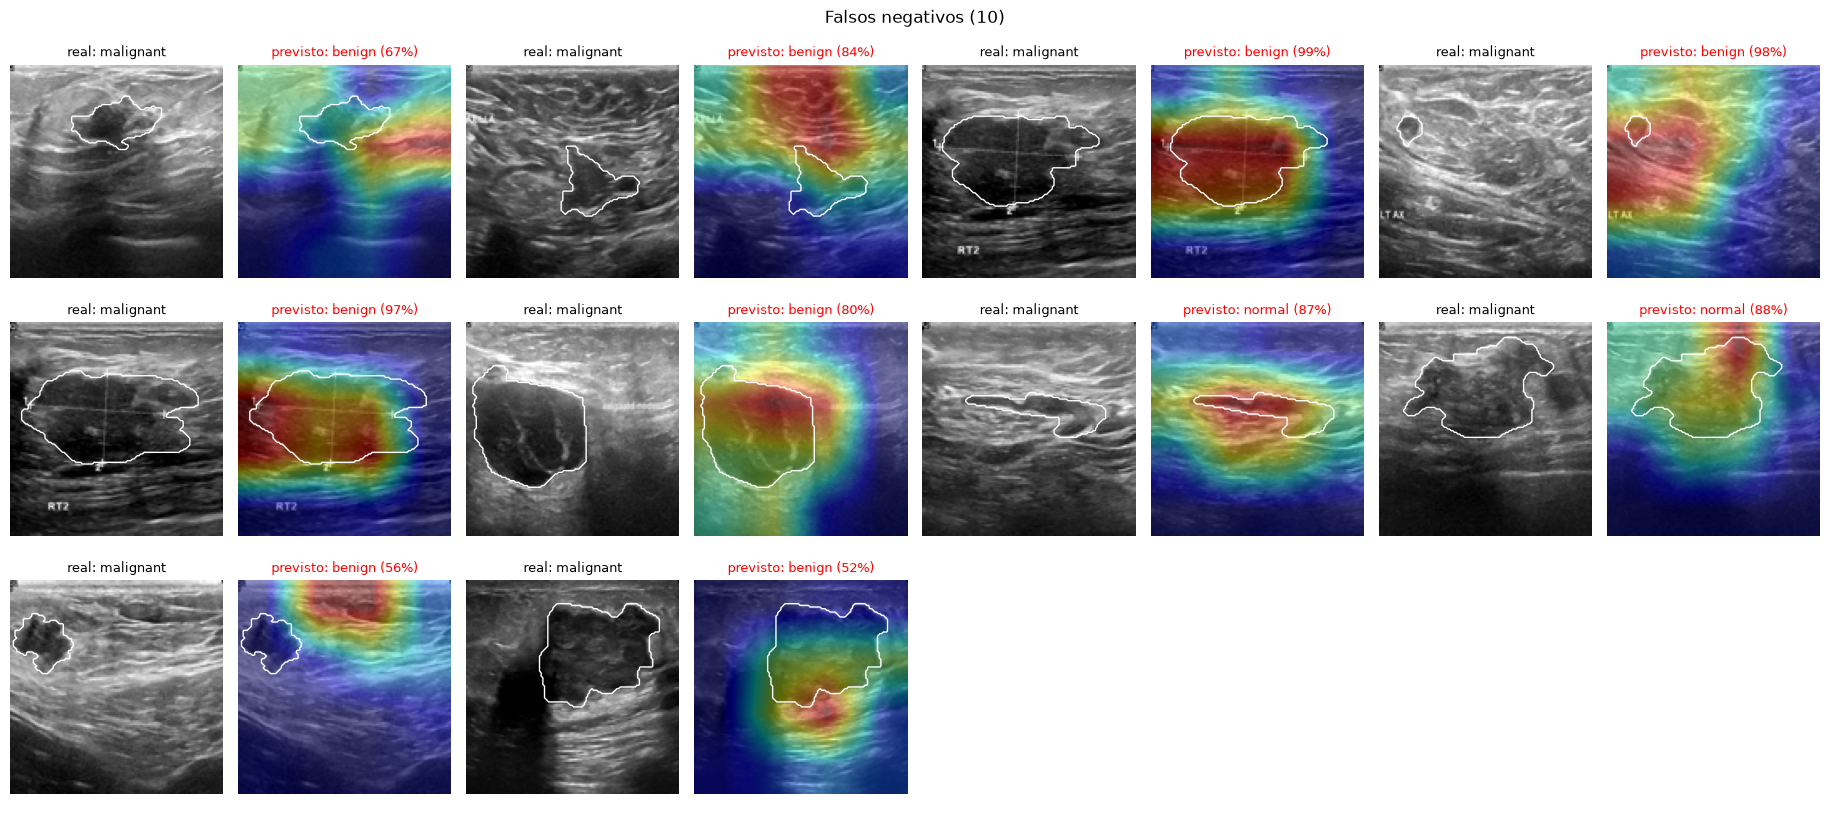

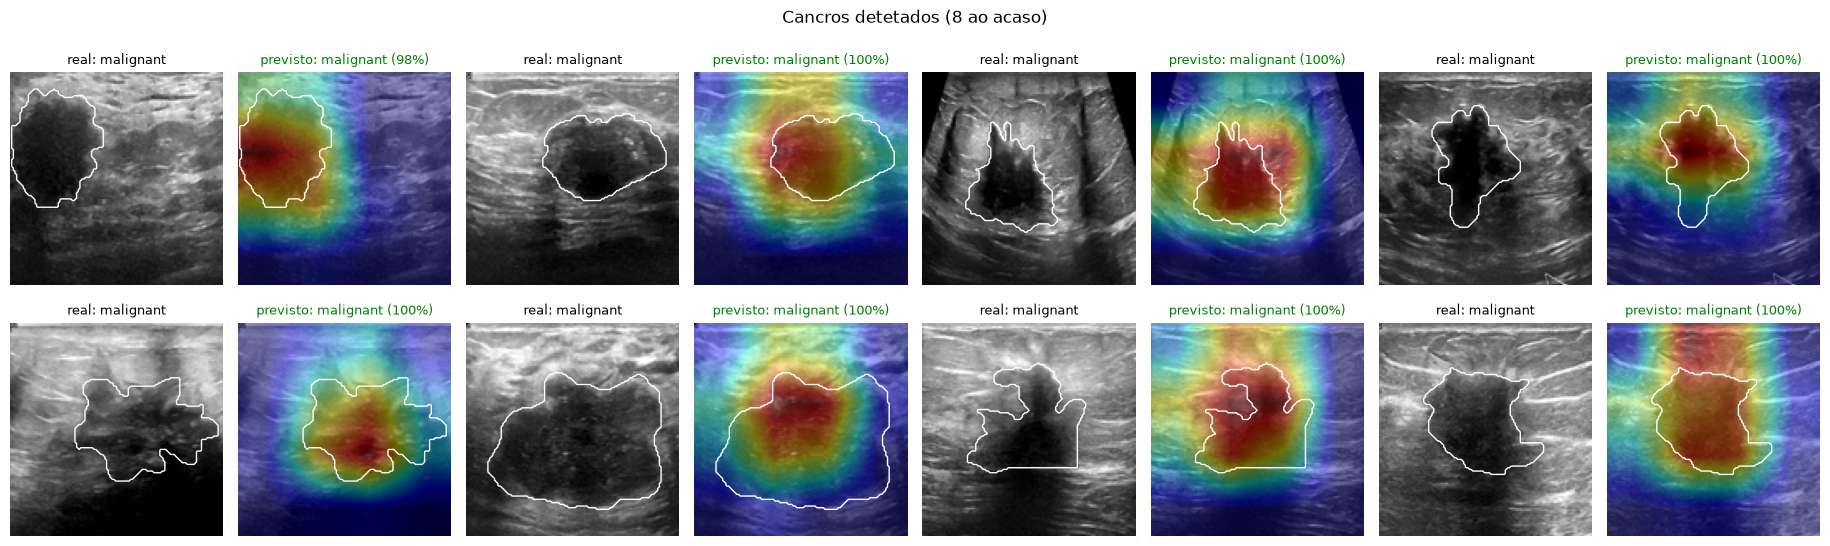

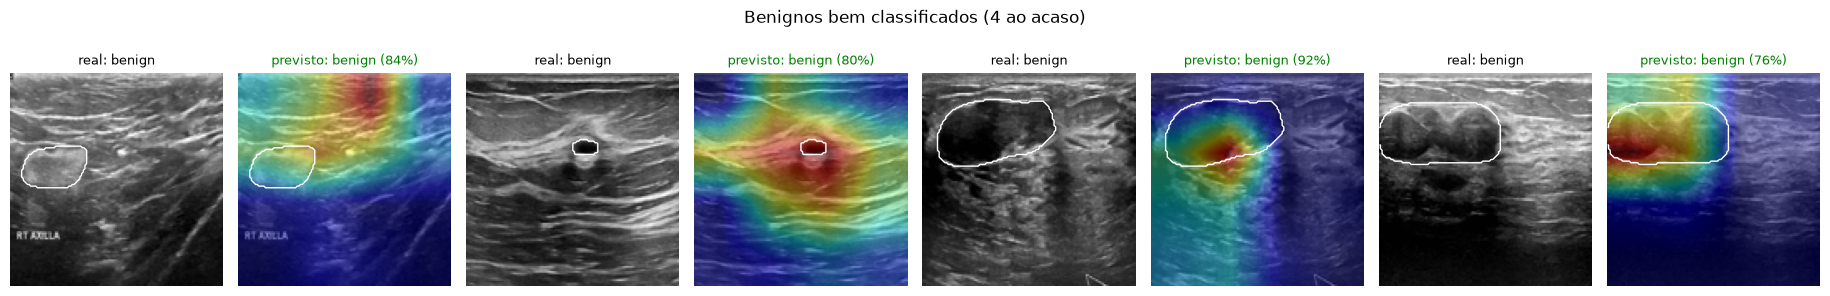

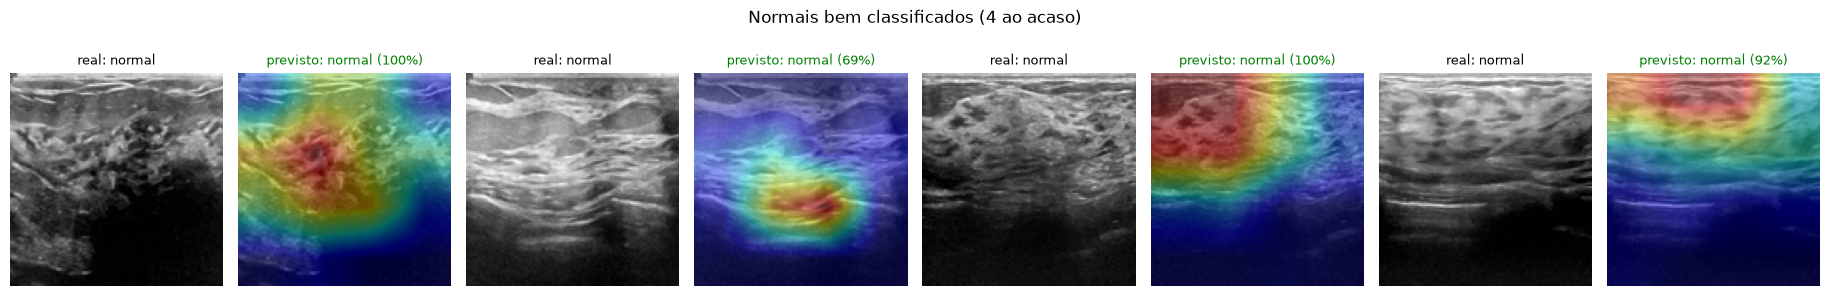

In [3]:
from src.explain import plot_grad_cam

explainer = GradCAM(model)
rng = np.random.default_rng(0)
false_negatives = np.where((y_test == MALIGNANT) & (y_pred != MALIGNANT))[0]
detected = np.where((y_test == MALIGNANT) & (y_pred == MALIGNANT))[0]
benign_ok = np.where((y_test == 1) & (y_pred == 1))[0]
normal_ok = np.where((y_test == 0) & (y_pred == 0))[0]

plot_grad_cam(explainer, x_test, y_test, false_negatives, f"Falsos negativos ({len(false_negatives)})", masks=masks)
plot_grad_cam(explainer, x_test, y_test, rng.choice(detected, 8, replace=False), "Cancros detetados (8 ao acaso)", masks=masks)
plot_grad_cam(explainer, x_test, y_test, rng.choice(benign_ok, 4, replace=False), "Benignos bem classificados (4 ao acaso)", masks=masks)
plot_grad_cam(explainer, x_test, y_test, rng.choice(normal_ok, 4, replace=False), "Normais bem classificados (4 ao acaso)", masks=masks)

## 5. O modelo olha para a lesão?

Para cada imagem de teste com lesão (benigna ou maligna) compara-se o Grad-CAM da classe prevista com a máscara da lesão (`lesion_overlap` em `src/explain.py`):

| Medida | O que mede |
|---|---|
| **Importância na lesão** | Fração da "importância" total do mapa que cai dentro da lesão. |
| **Área da lesão** | Fração da imagem ocupada pela lesão: é o valor anterior para um mapa que não olha para nada em especial. |

Se o modelo olha para a lesão, a importância na lesão deve ser bem maior do que a área da lesão. As imagens são separadas em acertos e erros para ver se os erros vêm de o modelo olhar para o sítio errado.

In [4]:
from src.explain import lesion_overlap

overlap = {i: lesion_overlap(explainer(x_test[i])[0], masks[i]) for i in np.where(y_test != 0)[0]}

groups = {
    "malignos detetados": detected,
    "malignos falhados (FN)": false_negatives,
    "benignos certos": np.where((y_test == 1) & (y_pred == 1))[0],
    "benignos errados": np.where((y_test == 1) & (y_pred != 1))[0],
}
print(f"{'grupo':<24}{'n':>4}{'importância na lesão':>23}{'área da lesão':>16}")
for name, idx in groups.items():
    if len(idx) == 0:
        continue
    energy = np.mean([overlap[i]["energy"] for i in idx])
    area = np.mean([overlap[i]["area"] for i in idx])
    print(f"{name:<24}{len(idx):>4}{energy:>23.0%}{area:>16.0%}")

grupo                      n   importância na lesão   área da lesão
malignos detetados        29                    35%             18%
malignos falhados (FN)    10                    24%             13%
benignos certos           63                    15%              7%
benignos errados          19                    13%              8%


## 6. Quando deve o modelo pedir ajuda ao médico?

O Grad-CAM ajuda a perceber uma previsão, mas alguém tem de decidir **que previsões** precisam de ser revistas. Uma regra simples para o agente (#7): se a probabilidade da classe prevista for menor do que um limiar, o caso vai para o médico. A tabela mostra, para vários limiares, quantas imagens de teste seriam enviadas ao médico e quantos erros (e falsos negativos) apanharíamos assim. Também se mostra a probabilidade de **maligno** que o modelo deu aos cancros que falhou: uma regra do tipo "maligno acima de 50% → médico" apanharia algum?

In [5]:
confidence = probs_test.max(axis=1)
errors = y_pred != y_test
is_fn = (y_test == MALIGNANT) & (y_pred != MALIGNANT)
print(f"{'limiar':>7}{'enviadas ao médico':>21}{'erros apanhados':>18}{'FN apanhados':>15}")
for threshold in [0.8, 0.9, 0.95, 0.99]:
    review = confidence < threshold
    print(f"{threshold:>7.0%}{review.sum():>12} ({review.mean():.0%}){(errors & review).sum():>11} de {errors.sum()}"
          f"{(is_fn & review).sum():>9} de {is_fn.sum()}")
print("\nProbabilidade de maligno nos falsos negativos:", np.round(np.sort(probs_test[is_fn, MALIGNANT]), 3))

 limiar   enviadas ao médico   erros apanhados   FN apanhados
    80%          44 (30%)         13 de 30        4 de 10
    90%          61 (41%)         21 de 30        7 de 10
    95%          73 (49%)         23 de 30        7 de 10
    99%          96 (64%)         27 de 30        9 de 10

Probabilidade de maligno nos falsos negativos: [0.    0.003 0.005 0.018 0.023 0.079 0.104 0.184 0.203 0.476]


## 7. Conclusões

1. **Quando deteta um cancro, o modelo olha para a lesão.** Nos 29 malignos detetados, 35% da importância do mapa cai dentro da lesão, que ocupa só 18% da imagem (quase o dobro do que um mapa ao acaso daria), e nos exemplos o vermelho está quase sempre em cima da lesão.
2. **Os falsos negativos têm duas causas diferentes.** Em alguns, o modelo olha para a lesão e mesmo assim diz "benigno": são lesões grandes, ovais e de contornos regulares, com aparência benigna. Noutros, sobretudo com lesões pequenas, olha para o tecido ao lado. No primeiro caso o problema é o que o modelo aprendeu; no segundo, nem chegou a "ver" a lesão.
3. **O Grad-CAM mostra a zona, não o pormenor.** Com imagens 128×128 o mapa é uma grelha 4×4: indica a região, mas não o contorno da lesão, que é o que distingue uma lesão benigna de uma maligna. Mesmo nos cancros detetados, cerca de dois terços do mapa caem fora da lesão. É uma ajuda para o médico decidir se confia na previsão, não uma prova de que o modelo está certo.
4. **O modelo está muitas vezes muito seguro quando erra.** 3 dos 10 falsos negativos têm confiança ≥ 97%, e a probabilidade de maligno que o modelo lhes dá é quase sempre baixa (9 em 10 abaixo de 25%): mesmo uma regra "maligno acima de 25% → médico" quase não os apanhava.
5. **Uma regra pela confiança apanha a maioria dos erros, com um custo.** Enviar ao médico os casos com confiança abaixo de 90% apanha 21 dos 30 erros e 7 dos 10 falsos negativos, mas envia 41% das imagens. É este o compromisso do Human-in-the-Loop no agente (#7): o médico revê cerca de 4 em cada 10 casos e o modelo trata dos restantes. O limiar foi visto aqui no teste; no agente (notebook 04) é escolhido com o conjunto de validação.